Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.8349 - loss: 0.5753 - val_accuracy: 0.9563 - val_loss: 0.1473
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9632 - loss: 0.1254 - val_accuracy: 0.9678 - val_loss: 0.1080
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9777 - loss: 0.0770 - val_accuracy: 0.9699 - val_loss: 0.0984
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9833 - loss: 0.0547 - val_accuracy: 0.9731 - val_loss: 0.0885
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9878 - loss: 0.0396 - val_accuracy: 0.9732 - val_loss: 0.0937
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9922 - loss: 0.0265 - val_accuracy: 0.9752 - val_loss: 0.0881
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9934 - loss: 0.0202 - val_accuracy: 0.9783 - val_loss: 0.0814
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9955 - loss: 0.0159 - val_acc

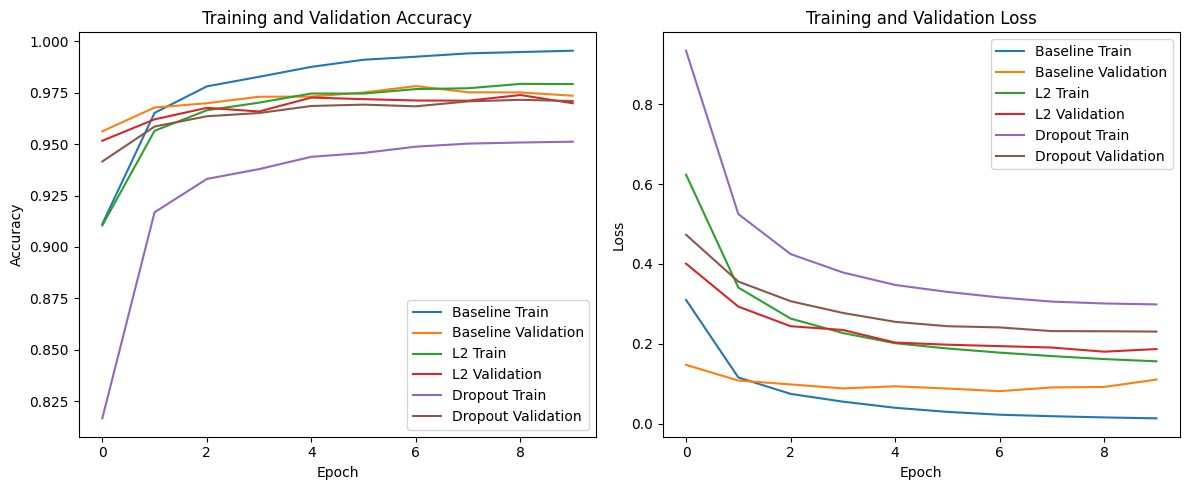

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize data
x_train = x_train / 255.0
x_test = x_test / 255.0

# Flatten images
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# =====================================================
# 1. Baseline Model (No Regularization)
# =====================================================

baseline = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

baseline.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_baseline = baseline.fit(
    x_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

# =====================================================
# 2. L2 Regularization Model
# =====================================================

l2_model = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(
        256,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dense(
        128,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dense(10, activation='softmax')
])

l2_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_l2 = l2_model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

# =====================================================
# 3. L2 + Dropout Model
# =====================================================

dropout_model = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(
        256,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.5),
    layers.Dense(
        128,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

dropout_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_dropout = dropout_model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

# =====================================================
# Test Accuracy
# =====================================================

print("Baseline Accuracy :", baseline.evaluate(x_test, y_test, verbose=0)[1])
print("L2 Accuracy       :", l2_model.evaluate(x_test, y_test, verbose=0)[1])
print("Dropout Accuracy  :", dropout_model.evaluate(x_test, y_test, verbose=0)[1])

# =====================================================
# Plot Accuracy
# =====================================================

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(history_baseline.history['accuracy'], label='Baseline Train')
plt.plot(history_baseline.history['val_accuracy'], label='Baseline Validation')

plt.plot(history_l2.history['accuracy'], label='L2 Train')
plt.plot(history_l2.history['val_accuracy'], label='L2 Validation')

plt.plot(history_dropout.history['accuracy'], label='Dropout Train')
plt.plot(history_dropout.history['val_accuracy'], label='Dropout Validation')

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# =====================================================
# Plot Loss
# =====================================================

plt.subplot(1,2,2)

plt.plot(history_baseline.history['loss'], label='Baseline Train')
plt.plot(history_baseline.history['val_loss'], label='Baseline Validation')

plt.plot(history_l2.history['loss'], label='L2 Train')
plt.plot(history_l2.history['val_loss'], label='L2 Validation')

plt.plot(history_dropout.history['loss'], label='Dropout Train')
plt.plot(history_dropout.history['val_loss'], label='Dropout Validation')

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()